# Coral bleaching: data cleaning and preprocessing

**Purpose.** Prepare a reproducible matrix of environmental measurements for a subsequent
principal component analysis (PCA). The research question concerns environmental patterns
associated with coral bleaching severity. This report covers **cleaning and preprocessing only**.
No PCA, component selection, prediction, or group-effect analysis is performed.

The unit of observation is a sampling event identified by `Sample_ID`. The workflow reads
`coral.csv`, documents quality checks and exclusions, and writes derived files to `processed/`.
Identifiers, outcomes, dates, locations, and missingness flags remain separate from the
environmental feature matrix.

## 1. Sources and reproducibility

The implementation consolidates the supplied `coral_eda_cleaning_preprocessing.ipynb`,
`coral_data_cleaning_summary.md`, and `data_dictionary.md`. The supplied
`coral_pca_ready.csv` was reviewed as a previous export. The downstream
`coral_pca_analysis.ipynb` was inspected for input expectations; its analyses are outside
this report's scope. These original files are preserved.

The raw file contains 41,361 substrate records and 62 columns. Its SHA-256 fingerprint
matches the one recorded in the original cleaning notebook. The original dictionary defines
variable meanings and units; it is retained alongside a generated column-role audit.

Run the notebook from the project folder using the versions in `requirements.txt`, or run
`python scripts/execute_notebook.py` for a fresh-kernel execution and HTML reading copy.
All reusable logic is imported from `coral_pipeline`; no cleaning functions are defined here.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
from IPython.display import display

from coral_pipeline.data import (
    INTERPRETATION_COLUMNS, column_roles, file_sha256, find_project_root,
    load_dictionary, load_raw, preprocessing_metadata, save_outputs,
)
from coral_pipeline.cleaning import (
    collapse_samples, filter_samples_from_year, filter_sparse_samples, normalise_types, retain_labelled_samples,
    sample_metadata, select_features, substrate_records, validate_dates, validate_measurements,
)
from coral_pipeline.preprocessing import build_processed_tables, fit_preprocessing, transform_features
from coral_pipeline.reporting import (
    configure_display, depth_missing_by_source, group_summary, missingness_table,
    plot_missingness, plot_transform_diagnostics, profile_features, retention_table, validate_ready,
)

configure_display()
ROOT = find_project_root()
MIN_SAMPLE_YEAR = 1998
MAX_MISSING_FRACTION = 0.50
NEAR_DUPLICATE_RHO = 0.999
SKEW_THRESHOLD = 0.75
RAW_HASH = file_sha256(ROOT / "coral.csv")
raw = load_raw(ROOT / "coral.csv")
dictionary = load_dictionary(ROOT / "data_dictionary.md")
print(f"Raw data: {len(raw):,} rows × {raw.shape[1]} columns")
print(f"SHA-256: {RAW_HASH}")
display(raw[["Sample_ID", "Site_ID", "Data_Source", "Depth_m", "Percent_Bleaching"]].head(3))

Raw data: 41,361 rows × 62 columns
SHA-256: 78cc014b1e7887f26f4c44a40d4d9213212f3c6217541c6a1b69e723b61bfacb


,Sample_ID,Site_ID,Data_Source,Depth_m,Percent_Bleaching
0,10324336,2501,Donner,10,50.2
1,10324754,3467,Donner,14,50.7
2,10323866,1794,Donner,7,50.9


## 2. Missing-value markers, data types, and validity

The source uses `nd` (no data). These text markers conceal missing observations and make
numeric columns load as text. Surrounding whitespace is stripped, case-insensitive `nd`
markers become missing values, and documented numeric fields are converted explicitly.
Unexpected numeric tokens cause an error rather than being silently discarded.

Identifiers and date parts must contain complete integer values. Recorded percentages,
coordinates, nonnegative physical quantities, and Kelvin temperatures are checked against
their basic valid ranges. Negative temperature anomalies remain valid. No unit conversion
is introduced; the dictionary's windspeed unit requires verification before physical interpretation.

In [2]:
typed, token_audit = normalise_types(raw)
measurement_checks = validate_measurements(typed)
print(f"'nd' cells replaced: {token_audit.nd_replaced.sum():,}")
print(f"Text columns converted to numeric: {token_audit.converted_to_numeric.sum()}")
print(f"Measurement range checks passed: {measurement_checks.passed.sum()} / {len(measurement_checks)}")
display(token_audit.loc[token_audit.nd_replaced.gt(0)].sort_values("nd_replaced", ascending=False))

'nd' cells replaced: 221,500
Text columns converted to numeric: 38
Measurement range checks passed: 33 / 33


,column,nd_replaced,converted_to_numeric,missing_after
59,Site_Comments,39104,False,39104
61,Bleaching_Comments,38692,False,38692
60,Sample_Comments,38403,False,38403
12,Site_Name,34429,False,34429
23,Bleaching_Level,18830,False,18830
21,Substrate_Name,12668,False,12668
6,Reef_ID,12540,False,12540
22,Percent_Cover,12455,True,12455
24,Percent_Bleaching,6846,True,6846
20,Depth_m,1799,True,1799


## 3. Consolidating substrate records into sampling events

Several records describe the same event but different substrates. Treating these records as
separate observations would give repeated events additional weight. Before aggregation,
the implementation requires every retained environmental field, date, location, identifier,
and descriptor to agree within `Sample_ID`, including missingness. Conflicts stop execution.

`Substrate_Name` and `Percent_Cover` cannot each be represented by one value per event.
They are preserved in a separate `coral_substrate_records.csv` table for the final cohort,
linked by `Sample_ID`, rather than averaged or assigned an arbitrary first value. The original decision to average differing bleaching percentages within an event
is retained and audited below. This unweighted mean assumes the substrate records provide
equally relevant bleaching summaries; no defensible alternative weights are supplied.
Exact duplicate records, if present, are removed before this mean is calculated.

Different sampling-event IDs remain distinct even when all non-ID values match. One row per
event prevents substrate repetition; it does **not** establish independence among repeated
surveys at the same site.

In [3]:
samples, grain_audit, outcome_conflicts = collapse_samples(typed)
display(grain_audit)
display(outcome_conflicts.rename(columns={"count": "recorded_values", "mean": "retained_mean"}))

,measure,value
0,Raw rows,41361
1,Exact duplicate rows removed,0
2,Distinct sampling events,27005
3,Events with differing recorded outcomes (averaged),8
4,Events identical on non-ID fields (retained),30


,Sample_ID,recorded_values,min,max,retained_mean
0,10290453,2,49.7200,55.3700,52.5450
1,10290456,2,28.3500,42.0400,35.1950
2,10290623,4,60.4800,78.1400,71.1750
3,10290626,2,61.0300,77.8500,69.4400
4,10290630,2,72.0800,76.1400,74.1100
5,10290633,2,66.8100,81.1900,74.0000
6,10323635,2,23.7000,66.7000,45.2000
7,10330547,2,0.7600,2.6100,1.6850


The source contains no exact duplicate records. Consolidation produces 27,005 events;
eight events have differing observed bleaching values. Thirty events match another event
on all non-ID fields and are retained as separate recorded observations.

## 4. Defining the cohort and preserving interpretation fields

The original research design compares bleaching-severity groups. Events without an observed
`Percent_Bleaching` are therefore excluded, and outcomes are never imputed. Although PCA
itself does not require outcomes, this restriction preserves the original requirement for
observed outcomes; the additional period restriction is applied below. It can affect representativeness and must be acknowledged in subsequent reporting.

The existing cut-points are retained: **Low** 0–10%, **Moderate** >10–50%, and **High** >50–100%.
The source `Bleaching_Comments` explicitly contains Mild (1–10%), Moderate (11–50%), and
Severe (>50%) code descriptions. Low additionally includes recorded zeros. These are fixed
study definitions rather than thresholds optimised using environmental measurements.
Some percentages are averages derived from codes, so they should not all be treated as
equally precise continuous measurements.

ISO dates must parse and agree exactly with their year, month, and day fields. The concentration
on particular days in the original audit suggests limited day precision; retain the recorded
dates and prefer year and month for later interpretation. Dates and coordinates are not inputs.

In [4]:
labelled = validate_dates(retain_labelled_samples(samples))
print(f"Events without a bleaching outcome excluded: {len(samples) - len(labelled):,}")
print(f"Labelled events: {len(labelled):,}")
print(f"Recorded date range in this cohort: {labelled.Date.min().date()} to {labelled.Date.max().date()}")
print(f"Share recorded on day 15: {100 * labelled.Date_Day.eq(15).mean():.1f}%")
display(group_summary(labelled))

Events without a bleaching outcome excluded: 3,734
Labelled events: 23,271
Recorded date range in this cohort: 1980-06-15 to 2020-08-15
Share recorded on day 15: 27.7%


,bleaching_group,samples,percent
0,Low,16996,73.0351
1,Moderate,4028,17.3091
2,High,2247,9.6558


## 4.1. Sampling-period restriction: retain 1998 onward

Events sampled in **1997 or earlier are excluded**. The lower boundary is inclusive:
a sampling year of 1998 is retained. The ISO sampling date must agree with `Date_Year`.
This requested study-period restriction is applied to labelled sampling events before
feature selection, missingness exclusion, imputation, power transformation, or scaling.
Consequently, fitted preprocessing statistics describe only the eligible period.

The exclusion table records event IDs and dates. The raw data remain unchanged;
the final cleaned table, standardised matrices, and interpretation sidecar all use
the same restricted cohort.

In [5]:
period_samples, year_exclusions = filter_samples_from_year(labelled, MIN_SAMPLE_YEAR)
print(f"Labelled events from {MIN_SAMPLE_YEAR - 1} or earlier excluded: {len(year_exclusions):,}")
print(f"Events retained from {MIN_SAMPLE_YEAR} onward before sparse-profile exclusion: {len(period_samples):,}")
print(f"Eligible date range: {period_samples.Date.min().date()} to {period_samples.Date.max().date()}")
display(year_exclusions.groupby("Date_Year").size().rename("excluded_events").to_frame())

Labelled events from 1997 or earlier excluded: 145
Events retained from 1998 onward before sparse-profile exclusion: 23,126
Eligible date range: 1998-01-15 to 2020-08-15


,excluded_events
Date_Year,
1980,2
1983,15
1986,3
1987,18
1988,6
1990,3
1991,7
1992,8
1993,9


## 5. Selecting environmental inputs

The feature set contains continuous environmental measurements and environmental counts.
`Percent_Bleaching` and its group are outcomes; IDs, dates, and geographic coordinates are
interpretation fields. Categorical labels and free-text comments, including comments describing
outcome derivation, are retained in the combined CSV as metadata. They are excluded only
from the PCA feature matrix. Nominal labels are not assigned artificial numeric scales.

In particular, `Exposure` is excluded from the feature matrix. The dictionary describes
“Sometimes” through a narrow exposure window and cyclone-season conditions, rather than
as a numerical midpoint between sheltered and exposed. No ordinal or one-hot encoding is
introduced. The earlier notebook noted that pooled exposure comparisons were sensitive to
data-source composition; source and exposure labels are preserved in both the combined CSV
and the metadata sidecar.

Constant features carry no variance and are excluded from PCA inputs, while their
original values remain in the combined CSV. The original near-duplicate threshold,
absolute Spearman correlation ≥ 0.999, is retained; the earlier column in source order is kept.
The near-duplicate column also remains in the combined CSV in original units, outside the
PCA input list. Rank correlation this high indicates near redundancy, not numerical equality.
Other correlated environmental families remain to preserve the original feature weighting.

In [6]:
features, removed_environmental, correlated_pairs = select_features(period_samples, NEAR_DUPLICATE_RHO)
roles = column_roles(raw.columns, dictionary, removed_environmental)
print(f"Environmental inputs retained: {len(features)}")
display(roles.groupby("role").size().rename("columns").to_frame())
display(roles.loc[roles.role.eq("Environmental metadata (retained)"), ["reason", "units"]])
display(correlated_pairs.loc[correlated_pairs.near_duplicate])

Environmental inputs retained: 35


,columns
role,
Category (retained),11
Environmental input,35
Environmental metadata (retained),2
Identifier,2
Interpretation,6
Outcome,1
Substrate detail (separate table),2
Text (retained),3


,reason,units
column,,
SSTA_Mean,Constant or entirely missing in the labelled cohort. Retain in original...,Degrees Celsius (°C)
TSA_Standard_Deviation,Near-duplicate of Temperature_Kelvin_Standard_Deviation: absolute Spear...,Degrees Celsius (°C)


,feature_a,feature_b,spearman_rho,near_duplicate
1,Temperature_Kelvin_Standard_Deviation,TSA_Standard_Deviation,1.0000,True


For this dataset, `SSTA_Mean` is constant and `TSA_Standard_Deviation` is a near duplicate
of `Temperature_Kelvin_Standard_Deviation`. The resulting feature set has 35 columns.
Both excluded environmental columns remain available in original units as metadata.
The full audit distinguishes retention in the sample table from eligibility for PCA inputs,
with descriptions, units, reasons, and high-correlation pairs.

## 6. Environmental completeness and sparse-event exclusion

Thermal variables are missing together in a small group of events. Filling most of an event's
environmental profile with typical values would give it little measured information. Following
the original rule, events missing **more than 50%** of the 35 retained inputs are excluded;
events missing exactly 50% would be retained. Missingness is evaluated before imputation.

Twelve most affected inputs; the complete missingness audit is exported.


,feature,missing,missing_percent
0,Depth_m,1611,6.9662
1,SSTA_Minimum,75,0.3243
2,Temperature_Kelvin,64,0.2767
3,SSTA,64,0.2767
4,SSTA_Frequency,64,0.2767
5,SSTA_DHW,64,0.2767
6,TSA,64,0.2767
7,TSA_Frequency,64,0.2767
8,TSA_DHW,64,0.2767
9,Temperature_Mean,57,0.2465


Sparse events excluded: 57


,stage,rows,removed_from_previous
0,Raw substrate records,41361,0
1,One row per Sample_ID,27005,14356
2,Observed bleaching outcome,23271,3734
3,Sampling year >= 1998,23126,145
4,At most 50% of environmental inputs missing,23069,57


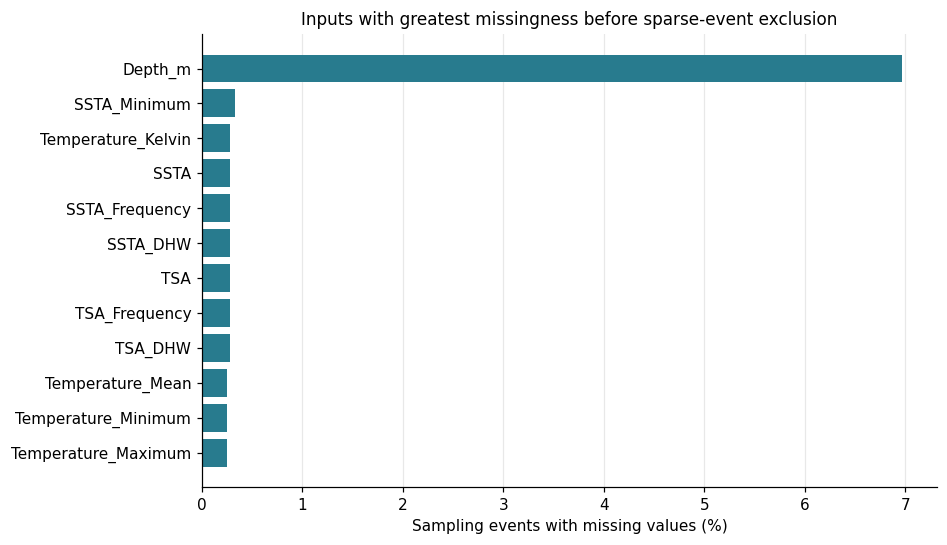

In [7]:
missing_before = missingness_table(period_samples, features)
print("Twelve most affected inputs; the complete missingness audit is exported.")
display(missing_before.loc[missing_before.missing.gt(0)].head(12))
missing_figure = plot_missingness(missing_before)
retained, sparse_exclusions = filter_sparse_samples(period_samples, features, MAX_MISSING_FRACTION)
retention = retention_table(raw, samples, labelled, period_samples, retained, MIN_SAMPLE_YEAR)
print(f"Sparse events excluded: {len(sparse_exclusions):,}")
display(retention)

After the year cutoff, the sparse-profile rule excludes 57 events, leaving **23,069 sampling events**.

## 7. Median imputation and missingness provenance

Remaining gaps are filled with feature medians fitted on the retained cohort. This preserves
the original robust, simple imputation method. The original-unit cleaned table contains these
imputed values for the 35 selected inputs, not the unaltered measurements.
Missing metadata values, including gaps in excluded environmental columns, are left unchanged. `Depth_m_was_missing` records depth
imputation and is excluded from the feature matrix.

Depth missingness is concentrated in particular sources and bleaching groups. The following
tables document that provenance. Median imputation can change variances and covariances
and place many events at one value; the flag and sidecar support later sensitivity checks.
No extra missingness indicators, outlier deletion, clipping, or synthetic observations are added.

In [8]:
imputed, scaled, fitted, transform_audit = fit_preprocessing(retained, features, SKEW_THRESHOLD)
display(transform_audit.loc[transform_audit.imputed_cells.gt(0),
                            ["feature", "median", "imputed_cells", "imputed_percent"]])
display(depth_missing_by_source(retained))
display(group_summary(retained))

,feature,median,imputed_cells,imputed_percent
0,Distance_to_Shore,662.5050,1,0.0043
3,Depth_m,6.4000,1608,6.9704
5,Temperature_Kelvin,301.7500,7,0.0303
10,Windspeed,5.0000,7,0.0303
11,SSTA,0.2800,7,0.0303
13,SSTA_Minimum,-3.4000,18,0.0780
15,SSTA_Frequency,6.0000,7,0.0303
19,SSTA_DHW,1.4600,7,0.0303
23,TSA,-0.6500,7,0.0303
27,TSA_Frequency,1.0000,7,0.0303


,Data_Source,samples,depth_missing,depth_missing_percent
0,AGRRA,2847,28,0.9835
1,Donner,5618,1571,27.9637
2,FRRP,2394,0,0.0000
3,Kumagai,660,0,0.0000
4,McClanahan,218,0,0.0000
5,Nuryana,5,5,100.0000
6,Reef_Check,11249,0,0.0000
7,Safaie,74,0,0.0000
8,Setiawan,4,4,100.0000


,bleaching_group,samples,percent,depth_imputed,depth_imputed_percent
0,Low,16905,73.2802,526,3.1115
1,Moderate,3986,17.2786,437,10.9634
2,High,2178,9.4412,645,29.6143


## 8. Selective transformation and standardisation

The original workflow transforms inputs with absolute sample skewness > 0.75 using
Yeo–Johnson, which accommodates zeros and negative anomalies, then standardises every
input. Other inputs are standardised directly. This retained choice reduces the influence of
long tails and different measurement scales. Normality is not a prerequisite for PCA, and
this transformation does not guarantee normal data or eliminate influential observations.

If a direct power fit is unstable, median/IQR scaling is attempted before fitting. The fitted
power, initial rescaling, and any numerical fallback are recorded per feature. A final
standardisation uses population standard deviation (`ddof=0`). The saved fitted state includes
medians and transformations in the exact feature order.

,feature,method,lambda,robust_rescale_first,skew_before,skew_after
0,Distance_to_Shore,yeo-johnson,-0.0590,False,9.2955,0.0176
1,Turbidity,yeo-johnson,-0.3964,True,3.8915,0.1432
2,Cyclone_Frequency,standardise only,NaN,False,0.7479,0.7479
3,Depth_m,yeo-johnson,0.2822,False,1.4063,-0.0033
4,ClimSST,yeo-johnson,2.5455,True,-1.6279,-0.1686
5,Temperature_Kelvin,yeo-johnson,1.5320,True,-1.0774,0.0873
6,Temperature_Mean,yeo-johnson,1.6350,True,-1.3707,-0.0059
7,Temperature_Minimum,yeo-johnson,2.2676,True,-1.4996,-0.0874
8,Temperature_Maximum,yeo-johnson,0.7593,True,0.9505,-0.0099
9,Temperature_Kelvin_Standard_Deviation,yeo-johnson,-1.8801,False,1.4129,0.1783


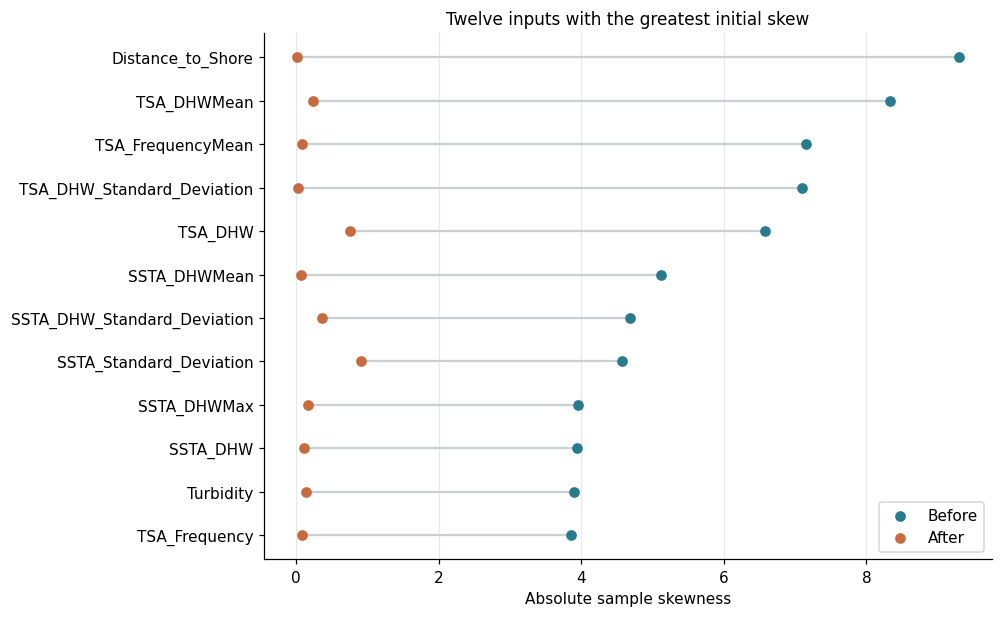

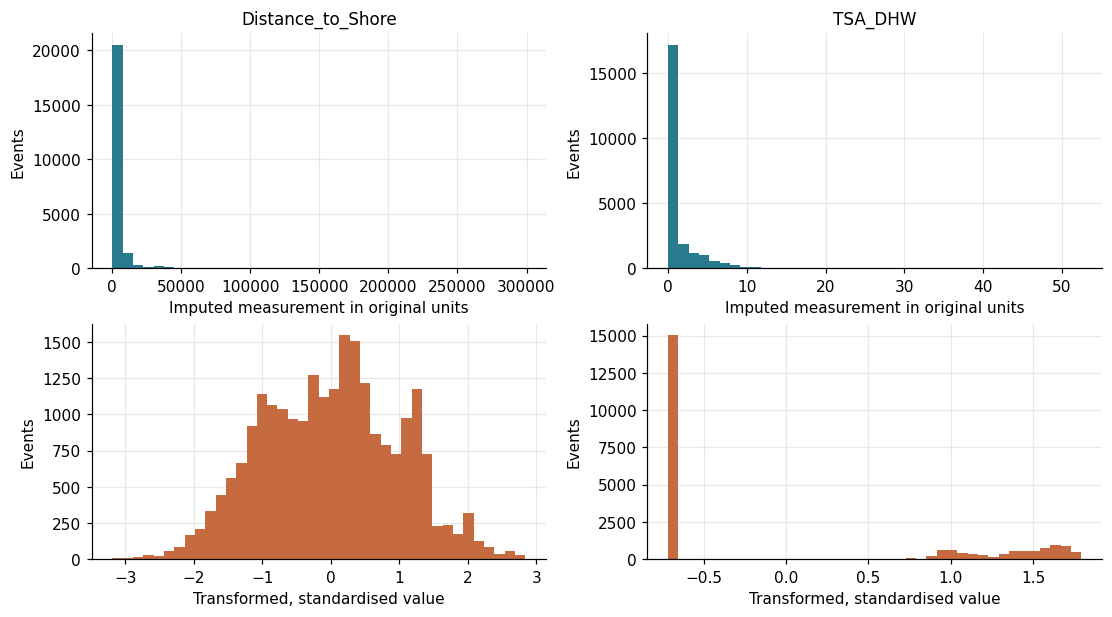

In [9]:
display(transform_audit[["feature", "method", "lambda", "robust_rescale_first", "skew_before", "skew_after"]])
skew_figure, distribution_figure = plot_transform_diagnostics(transform_audit, imputed, scaled)

Thirty-one inputs receive Yeo–Johnson transformation. `Cyclone_Frequency`, `Windspeed`,
`SSTA`, and `SSTA_FrequencyMax` are standardised directly. The same skewness rule is
refitted on the retained period, so `Cyclone_Frequency` now falls below its threshold. Five temperature or climatology columns and
`Turbidity` require the recorded rescaling step. Some inputs retain skew, particularly those
with a large concentration at zero; no further distributional transformation is introduced.

**Fitting scope and leakage.** This is a descriptive preparation of the retained 1998-onward cohort.
Outcomes, groups, and comments are never used to fit feature transformations. Outcome
availability determines cohort membership, as documented above. For any subsequent
prediction evaluation, split sample-level data by site (and by time if forecasting) **before**
fitting feature selection, imputation, transformations, scaling, or PCA. Fit each stage only on
the training fold and apply the fitted state to held-out observations. Do not use this globally
fitted matrix to claim unbiased predictive performance. The dictionary also describes thermal
summaries over the full historical period; their temporal availability needs review before prediction.

## 9. Final tables and validation

The original-unit cleaned table and standardised table contain the same events in the same
order, preserving all 60 source columns that have a sample-level meaning, plus the
bleaching group and depth-missingness flag: **62 columns in total**. Of these, 35 are
processed environmental inputs and 27 are metadata fields. A numeric-only matrix
contains exactly the environmental columns. Its row order matches both the combined table
and the metadata sidecar. Read the feature list from the exported metadata rather than
selecting every numeric column: IDs, outcomes, dates, coordinates, the depth flag,
and excluded environmental measurements are numeric too. Comments and categories
remain readable text; preserving them does not make them PCA inputs.

Readiness checks require sampling years from 1998 onward, finite numeric inputs,
nonconstant columns, near-zero means,
unit population standard deviations, consistent groups and dates, unique event IDs, and
row alignment. Additional checks verify preservation of all sample-level source columns
and unchanged metadata values between cleaned and standardised outputs. These checks establish numerical readiness without fitting PCA.

In [10]:
cleaned, ready = build_processed_tables(retained, imputed, scaled)
metadata_sidecar = sample_metadata(retained, features)
substrate_detail = substrate_records(typed, retained)
readiness = validate_ready(cleaned, ready, features, MIN_SAMPLE_YEAR)
np.testing.assert_allclose(transform_features(retained, fitted), scaled, rtol=1e-10, atol=1e-10)
display(readiness)
display(pd.DataFrame({
    "measure": ["Final sampling events", "Unique sites", "Environmental inputs", "Non-PCA columns",
                "Largest absolute input mean", "Largest deviation of population SD from one"],
    "value": [len(ready), ready.Site_ID.nunique(), len(features), len(metadata_sidecar.columns),
              scaled.mean().abs().max(), (scaled.std(ddof=0) - 1).abs().max()],
}))
print(f"Final recorded date range: {ready.Date.min().date()} to {ready.Date.max().date()}")

,check,passed
0,Feature list is nonempty and unique,True
1,No metadata or outcome in the feature matrix,True
2,Every feature has a numeric dtype,True
3,No missing or infinite feature values,True
4,No constant feature,True
5,All feature means within 1e-6 of zero,True
6,All population standard deviations within 1e-6 of one,True
7,One complete Sample_ID per row,True
8,Complete Site_ID values,True
9,No missing or out-of-range bleaching outcomes,True


,measure,value
0,Final sampling events,"23,069.0000"
1,Unique sites,"10,941.0000"
2,Environmental inputs,35.0000
3,Non-PCA columns,27.0000
4,Largest absolute input mean,0.0000
5,Largest deviation of population SD from one,0.0000


Final recorded date range: 1998-01-15 to 2019-12-31


The final date range is 1998–2019. A 2020 date appears in the earlier labelled cohort but does
not survive the sparse-profile exclusion. The distinction follows the sequence of cohort rules.

## 10. Exported deliverables and methodological limits

| File in `processed/` | Purpose |
|---|---|
| `coral_pca_features.csv` | Numeric-only, 23,069 × 35 input matrix; already transformed and standardised |
| `coral_pca_ready.csv` | 23,069 × 62 combined table: all sample-level source columns plus the two derived metadata fields |
| `coral_cleaned.csv` | Same 62 columns; selected inputs in original units after median imputation |
| `coral_sample_metadata.csv` | All 27 non-PCA columns, including categories, comments, and excluded environmental fields |
| `coral_substrate_records.csv` | Original substrate labels, cover values, and bleaching values for retained events, linked by event IDs |
| `coral_preprocessing_metadata.json` | Ordered feature list, fit scope, thresholds, exclusions, audits, versions, and fingerprints |
| `coral_transformers.joblib` | Fitted medians and per-feature transformations; load with the recorded environment |
| `year_exclusions.csv` | Labelled events dated 1997 or earlier, removed before fitting |
| Audit CSVs | Column roles, missingness, outcome aggregation, cohort retention, transformations, and checks |

The raw dataset and previous export are never overwritten. Original-unit measurement
profiles are saved as a quality audit; IQR extremes are descriptive flags, not removal rules.
The three preprocessing figures are also saved for inspection and reuse. The execution
script creates an HTML reading copy of this report.

In [11]:
metadata = preprocessing_metadata(roles, transform_audit, retention, MAX_MISSING_FRACTION, NEAR_DUPLICATE_RHO, MIN_SAMPLE_YEAR)
tables = {
    "column_roles": roles.reset_index(), "token_audit": token_audit,
    "measurement_checks": measurement_checks, "sample_grain_audit": grain_audit,
    "outcome_aggregation_audit": outcome_conflicts, "high_correlation_pairs": correlated_pairs,
    "missingness_before_imputation": missing_before, "sparse_event_exclusions": sparse_exclusions,
    "cohort_retention": retention, "year_exclusions": year_exclusions,
    "coral_substrate_records": substrate_detail,
    "transformation_audit": transform_audit,
    "depth_missingness_by_source": depth_missing_by_source(retained),
    "final_group_summary": group_summary(retained),
    "original_unit_feature_profile": profile_features(retained, features), "readiness_checks": readiness,
}
exports = save_outputs(ROOT, RAW_HASH, cleaned, ready, metadata_sidecar, fitted, metadata, tables)
figure_directory = ROOT / "processed" / "figures"
figure_directory.mkdir(exist_ok=True)
missing_figure.savefig(figure_directory / "input_missingness.png", dpi=150, bbox_inches="tight")
skew_figure.savefig(figure_directory / "skewness_change.png", dpi=150, bbox_inches="tight")
distribution_figure.savefig(figure_directory / "transformation_examples.png", dpi=150, bbox_inches="tight")
assert file_sha256(ROOT / "coral.csv") == RAW_HASH
print("Raw input unchanged: SHA-256 verified.")
display(exports.head(4))
print(f"Readiness checks passed: {readiness.passed.sum()} / {len(readiness)}. No PCA was performed.")

Raw input unchanged: SHA-256 verified.


,file,rows,columns
0,coral_cleaned.csv,23069,62
1,coral_pca_ready.csv,23069,62
2,coral_sample_metadata.csv,23069,27
3,coral_pca_features.csv,23069,35


Readiness checks passed: 20 / 20. No PCA was performed.


The original cleaning intent is preserved with the requested restriction to 1998 onward:
one event per sample ID, fixed severity groups,
nominal labels and comments retained as metadata, the constant and near-duplicate
measurements retained outside PCA inputs, sparse events
excluded, remaining gaps median-imputed, and selective transformation followed by scaling.
The implementation strengthens schema, within-event, date, and output checks and preserves
all sample-level source columns for later interpretation. Substrate-specific fields
remain in their separate detail table because they have multiple records per event.

Limitations to carry forward are the labelled-cohort and sampling-period restrictions,
repeated sites, source-related
depth missingness, imputation effects on covariance, approximate day precision, remaining
zero-heavy distributions, and unequal representation of correlated thermal families.
These issues are documented rather than addressed through additional unsupported transformations.
The resulting matrices are ready for the next PCA stage; that analysis is intentionally deferred.